In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
base_path = "/content/drive/MyDrive/Statistical Modelling Project/02_Clean_Data/"

In [78]:
import os
print(os.listdir(base_path))

['online_retail_clean', 'online_retail_merchandise', 'order_level_data', 'customer_level_data']


In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_clean = pd.read_csv(base_path + "online_retail_clean")
df_merchandise = pd.read_csv(base_path + "online_retail_merchandise")
df_orders = pd.read_csv(base_path + "order_level_data")
df_customers = pd.read_csv(base_path + "customer_level_data")

In [26]:
df_orders["OrderDate"] = pd.to_datetime(df_orders["OrderDate"])

df_customers["FirstPurchaseDate"] = pd.to_datetime(
    df_customers["FirstPurchaseDate"]
)

df_customers["LastPurchaseDate"] = pd.to_datetime(
    df_customers["LastPurchaseDate"]
)

In [27]:
print("Orders:", df_orders.shape)
print("Customers:", df_customers.shape)

print(df_orders.dtypes)
print(df_customers.dtypes)

Orders: (36644, 11)
Customers: (5863, 32)
Invoice                            int64
CustomerID                       float64
OrderDate                 datetime64[ns]
Country                           object
SourceYear                        object
OrderValue                       float64
TotalQuantity                      int64
ProductLines                       int64
UniqueProducts                     int64
DaysSincePreviousOrder           float64
PurchaseDate                      object
dtype: object
CustomerID                          float64
Frequency                             int64
Monetary                            float64
AverageOrderValue                   float64
TotalQuantity                         int64
AverageBasketQuantity               float64
AverageUniqueProducts               float64
FirstPurchaseDate            datetime64[ns]
LastPurchaseDate             datetime64[ns]
Recency                               int64
CustomerTenure                        int64
ProductDi

In [28]:
total_customers = df_customers["CustomerID"].nunique()
total_orders = df_orders["Invoice"].nunique()
total_revenue = df_orders["OrderValue"].sum()

avg_order_value = df_orders["OrderValue"].mean()
median_order_value = df_orders["OrderValue"].median()

avg_orders_per_customer = df_customers["Frequency"].mean()
median_orders_per_customer = df_customers["Frequency"].median()

print("Total customers:", total_customers)
print("Total orders:", total_orders)
print("Total revenue:", round(total_revenue, 2))

print("Average order value:", round(avg_order_value, 2))
print("Median order value:", round(median_order_value, 2))

print(
    "Average orders per customer:",
    round(avg_orders_per_customer, 2)
)

print(
    "Median orders per customer:",
    round(median_orders_per_customer, 2)
)

Total customers: 5863
Total orders: 36644
Total revenue: 17085797.18
Average order value: 466.26
Median order value: 302.57
Average orders per customer: 6.25
Median orders per customer: 3.0


In [29]:
repeat_customer_count = (
    df_customers["Frequency"] > 1
).sum()

one_time_customer_count = (
    df_customers["Frequency"] == 1
).sum()

repeat_customer_pct = (
    repeat_customer_count / total_customers
) * 100

one_time_customer_pct = (
    one_time_customer_count / total_customers
) * 100

print(
    "Customers with more than one order:",
    repeat_customer_count
)

print(
    "One-time customers:",
    one_time_customer_count
)

print(
    "Repeat customer percentage:",
    round(repeat_customer_pct, 2),
    "%"
)

print(
    "One-time customer percentage:",
    round(one_time_customer_pct, 2),
    "%"
)

Customers with more than one order: 4236
One-time customers: 1627
Repeat customer percentage: 72.25 %
One-time customer percentage: 27.75 %


**Analyse Purchase Frequency**-how many orders customers typically place

In [30]:
df_customers["Frequency"].describe()

,Frequency
count,5863.000000
mean,6.250043
std,12.790250
min,1.000000
25%,1.000000
50%,3.000000
75%,7.000000
max,378.000000


In [31]:
print(
    "Frequency skewness:",
    df_customers["Frequency"].skew()
)

Frequency skewness: 12.143307950223985


In [32]:
df_customers["Frequency"].value_counts().sort_index().head(20)

,count
Frequency,
1,1627
2,946
3,658
4,491
5,353
6,279
7,219
8,173
9,156


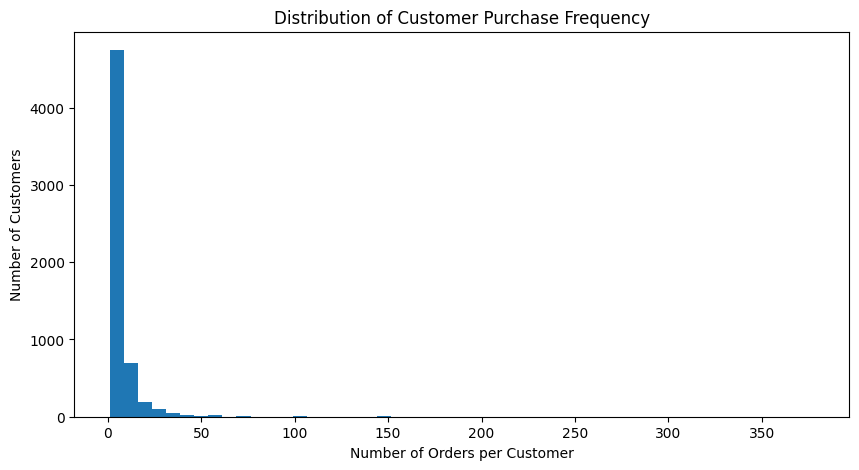

In [33]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["Frequency"],
    bins=50
)

plt.xlabel("Number of Orders per Customer")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Purchase Frequency")

plt.show()

**Analyse Monetary Value**

In [34]:
df_customers["Monetary"].describe()

,Monetary
count,5863.00000
mean,2914.17315
std,14327.73229
min,0.00000
25%,338.55500
50%,854.99000
75%,2236.94500
max,580987.04000


In [35]:
print(
    "Monetary skewness:",
    df_customers["Monetary"].skew()
)

Monetary skewness: 25.30983586258216


In [36]:
df_customers.nlargest(
    20,
    "Monetary"
)[
    [
        "CustomerID",
        "Frequency",
        "Monetary",
        "AverageOrderValue",
        "ProductDiversity"
    ]
]

,CustomerID,Frequency,Monetary,AverageOrderValue,ProductDiversity
5677,18102.0,145,580987.04,4006.807172,382
2271,14646.0,146,526751.52,3607.887123,961
1786,14156.0,151,305259.17,2021.583907,1445
2529,14911.0,378,280026.15,740.809921,2548
5037,17450.0,51,244784.25,4799.691176,145
1329,13694.0,143,195640.69,1368.116713,896
5096,17511.0,60,172132.87,2868.881167,657
4048,16446.0,2,168472.50,84236.250000,3
4282,16684.0,55,147142.77,2675.323091,184
68,12415.0,24,144033.37,6001.390417,496


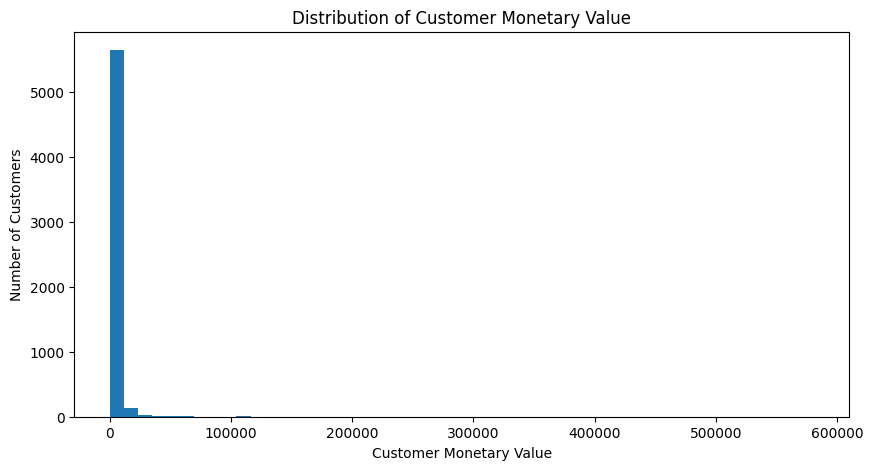

In [37]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["Monetary"],
    bins=50
)

plt.xlabel("Customer Monetary Value")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Monetary Value")

plt.show()

**Analyse Recency**-how recently customers purchased

In [38]:
df_customers["Recency"].describe()

,Recency
count,5863.000000
mean,200.956848
std,209.216692
min,1.000000
25%,26.000000
50%,96.000000
75%,379.000000
max,739.000000


In [39]:
print(
    "Recency skewness:",
    df_customers["Recency"].skew()
)

Recency skewness: 0.8918695123800069


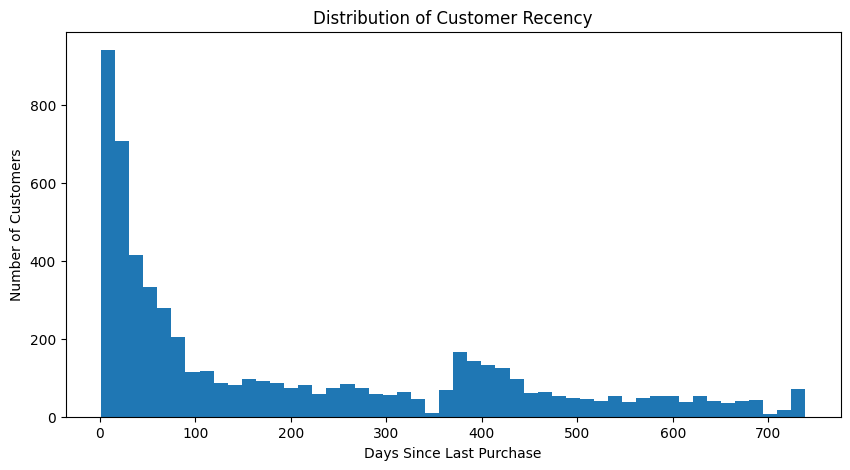

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["Recency"],
    bins=50
)

plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Recency")

plt.show()

**Compare RFM variables together**

In [41]:
rfm_summary = df_customers[
    ["Recency", "Frequency", "Monetary"]
].describe().T

rfm_summary

,count,mean,std,min,25%,50%,75%,max
Recency,5863.0,200.956848,209.216692,1.0,26.000,96.00,379.000,739.00
Frequency,5863.0,6.250043,12.790250,1.0,1.000,3.00,7.000,378.00
Monetary,5863.0,2914.173150,14327.732290,0.0,338.555,854.99,2236.945,580987.04


In [42]:
rfm_skewness = df_customers[
    ["Recency", "Frequency", "Monetary"]
].skew()

print(rfm_skewness)

Recency       0.891870
Frequency    12.143308
Monetary     25.309836
dtype: float64


**Analyse Average Order Value**-how much a customer typically spends per order

In [43]:
df_customers["AverageOrderValue"].describe()

,AverageOrderValue
count,5863.000000
mean,382.769145
std,1233.906830
min,0.000000
25%,175.745357
50%,277.516000
75%,410.516250
max,84236.250000


In [44]:
print(
    "Average Order Value skewness:",
    df_customers["AverageOrderValue"].skew()
)

Average Order Value skewness: 55.157848214427155


In [45]:
df_customers.nlargest(
    20,
    "AverageOrderValue"
)[
    [
        "CustomerID",
        "Frequency",
        "Monetary",
        "AverageOrderValue",
        "AverageBasketQuantity",
        "ProductDiversity"
    ]
]

,CustomerID,Frequency,Monetary,AverageOrderValue,AverageBasketQuantity,ProductDiversity
4048,16446.0,2,168472.50,84236.250000,40498.500000,3
0,12346.0,4,77353.96,19338.490000,18560.000000,26
3360,15749.0,3,44534.30,14844.766667,6009.333333,5
2713,15098.0,3,39916.50,13305.500000,40.333333,1
1322,13687.0,1,11880.84,11880.840000,87167.000000,45
5627,18052.0,1,10877.18,10877.180000,17766.000000,16
243,12590.0,1,9341.26,9341.260000,4282.000000,67
11,12357.0,2,17437.66,8718.830000,3293.000000,260
1535,13902.0,5,34023.26,6804.652000,44119.200000,57
68,12415.0,24,144033.37,6001.390417,3822.458333,496


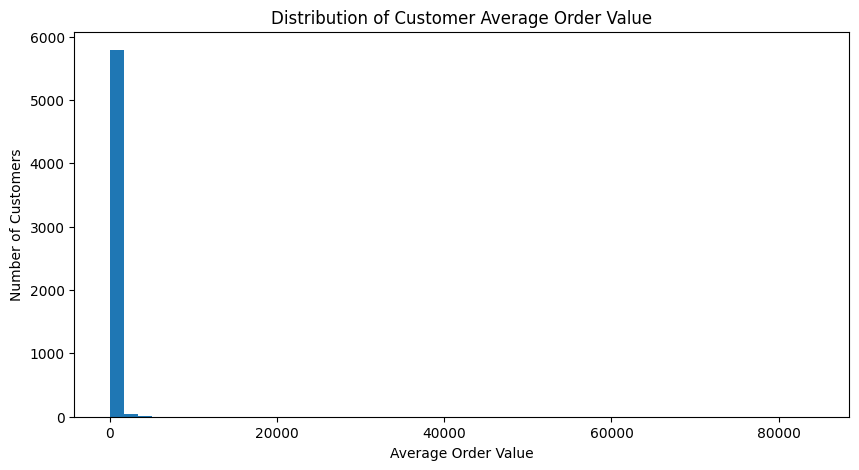

In [46]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["AverageOrderValue"],
    bins=50
)

plt.xlabel("Average Order Value")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Average Order Value")

plt.show()

**Analyse Basket Quantity**

In [47]:
df_customers["AverageBasketQuantity"].describe()

,AverageBasketQuantity
count,5863.000000
mean,255.162760
std,1456.701726
min,1.000000
25%,91.763889
50%,154.724138
75%,259.090909
max,87167.000000


In [48]:
print(
    "Average Basket Quantity skewness:",
    df_customers["AverageBasketQuantity"].skew()
)

Average Basket Quantity skewness: 45.35736542330935


In [49]:
df_customers.nlargest(
    20,
    "AverageBasketQuantity"
)[
    [
        "CustomerID",
        "Frequency",
        "AverageBasketQuantity",
        "AverageOrderValue",
        "Monetary",
        "ProductDiversity"
    ]
]

,CustomerID,Frequency,AverageBasketQuantity,AverageOrderValue,Monetary,ProductDiversity
1322,13687.0,1,87167.000000,11880.840000,11880.84,45
1535,13902.0,5,44119.200000,6804.652000,34023.26,57
4048,16446.0,2,40498.500000,84236.250000,168472.50,3
0,12346.0,4,18560.000000,19338.490000,77353.96,26
5627,18052.0,1,17766.000000,10877.180000,10877.18,16
902,13256.0,1,12540.000000,0.000000,0.00,1
1906,14277.0,8,11225.250000,2098.645000,16789.16,332
3360,15749.0,3,6009.333333,14844.766667,44534.30,5
5517,17940.0,15,5676.466667,1895.928667,28438.93,10
5826,18251.0,9,4404.333333,2919.873333,26278.86,87


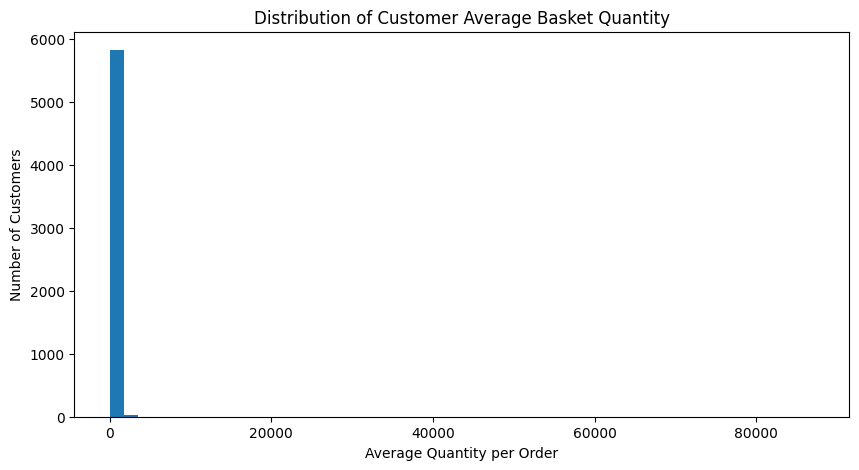

In [50]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["AverageBasketQuantity"],
    bins=50
)

plt.xlabel("Average Quantity per Order")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Average Basket Quantity")

plt.show()

**Analyse Product Diversity**

In [51]:
df_customers["ProductDiversity"].describe()

,ProductDiversity
count,5863.000000
mean,82.049974
std,116.464707
min,1.000000
25%,19.000000
50%,45.000000
75%,103.000000
max,2548.000000


In [52]:
print(
    "Product Diversity skewness:",
    df_customers["ProductDiversity"].skew()
)

Product Diversity skewness: 6.22662610779259


In [53]:
df_customers.nlargest(
    20,
    "ProductDiversity"
)[
    [
        "CustomerID",
        "Frequency",
        "Monetary",
        "ProductDiversity",
        "AverageUniqueProducts",
        "CustomerTenure"
    ]
]

,CustomerID,Frequency,Monetary,ProductDiversity,AverageUniqueProducts,CustomerTenure
2529,14911.0,378,280026.15,2548,29.256614,737
399,12748.0,323,49564.28,2285,19.746130,734
5419,17841.0,211,68519.95,2115,57.601896,735
1786,14156.0,151,305259.17,1445,26.682119,728
1927,14298.0,82,91194.49,1370,34.926829,719
2231,14606.0,184,29648.75,1259,34.163043,735
1728,14096.0,17,53258.43,1118,297.882353,97
2271,14646.0,146,526751.52,961,26.171233,735
2130,14505.0,19,11873.08,897,80.473684,713
1329,13694.0,143,195640.69,896,10.622378,731


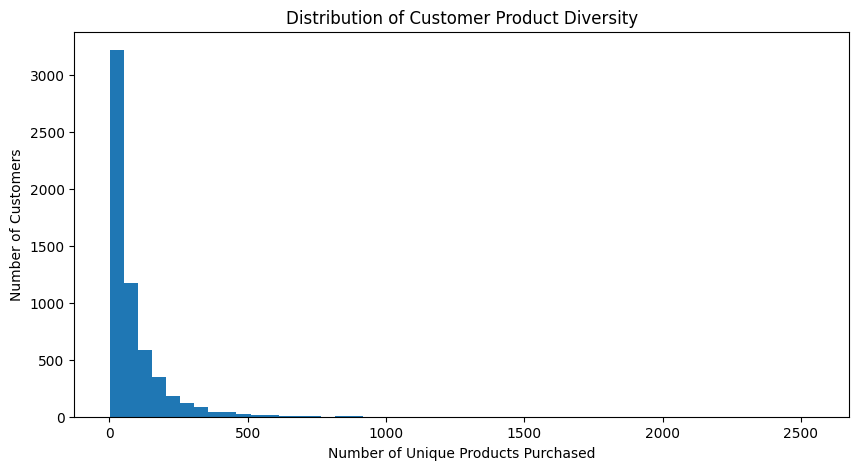

In [54]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["ProductDiversity"],
    bins=50
)

plt.xlabel("Number of Unique Products Purchased")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Product Diversity")

plt.show()

**Analyse Customer Tenure**

In [55]:
df_customers["CustomerTenure"].describe()

,CustomerTenure
count,5863.000000
mean,273.107965
std,258.522024
min,0.000000
25%,0.000000
50%,221.000000
75%,511.000000
max,738.000000


In [56]:
print(
    "Customer Tenure skewness:",
    df_customers["CustomerTenure"].skew()
)

Customer Tenure skewness: 0.3878526559980682


In [57]:
zero_tenure = (
    df_customers["CustomerTenure"] == 0
).sum()

print("Customers with zero tenure:", zero_tenure)

print(
    "Percentage with zero tenure:",
    round(
        zero_tenure / len(df_customers) * 100,
        2
    ),
    "%"
)

Customers with zero tenure: 1689
Percentage with zero tenure: 28.81 %


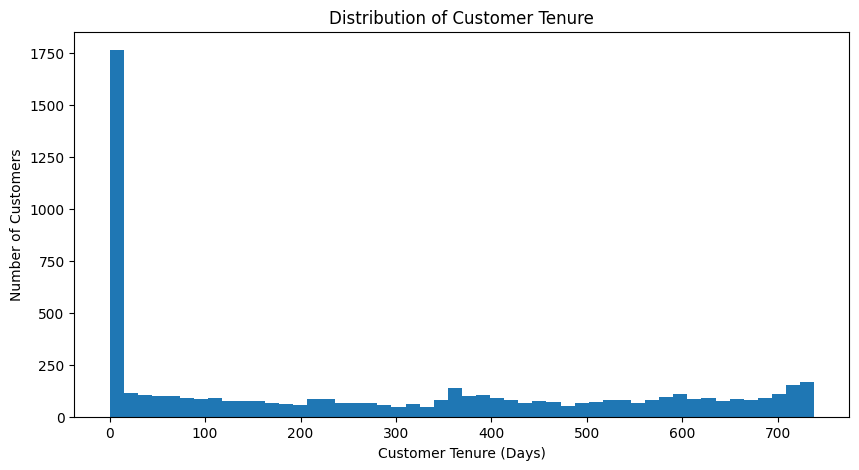

In [58]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["CustomerTenure"],
    bins=50
)

plt.xlabel("Customer Tenure (Days)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Tenure")

plt.show()

**Analyse Average Purchase Interval**

In [59]:
df_customers["AveragePurchaseInterval"].describe()

,AveragePurchaseInterval
count,4236.000000
mean,103.057291
std,99.337160
min,0.000000
25%,38.891667
50%,72.400000
75%,130.500000
max,714.000000


In [60]:
print(
    "Average Purchase Interval skewness:",
    df_customers["AveragePurchaseInterval"].skew()
)

Average Purchase Interval skewness: 2.1723787258141662


In [61]:
print(
    "Customers without a calculable purchase interval:",
    df_customers["AveragePurchaseInterval"].isna().sum()
)

Customers without a calculable purchase interval: 1627


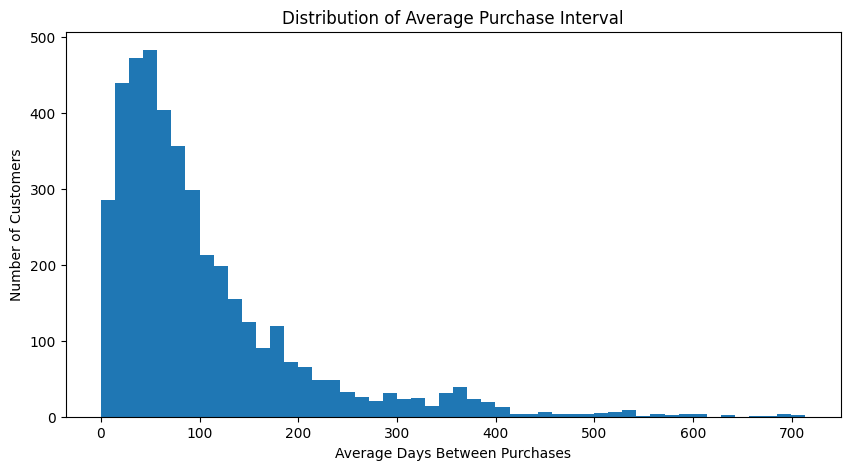

In [62]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["AveragePurchaseInterval"].dropna(),
    bins=50
)

plt.xlabel("Average Days Between Purchases")
plt.ylabel("Number of Customers")
plt.title("Distribution of Average Purchase Interval")

plt.show()

**Analyse Return Behaviour**

In [63]:
df_customers[
    [
        "ReturnTransactions",
        "ReturnedQuantity",
        "TotalReturnValue",
        "ReturnRate"
    ]
].describe()

,ReturnTransactions,ReturnedQuantity,TotalReturnValue,ReturnRate
count,5863.000000,5863.000000,5863.000000,5863.000000
mean,1.267952,79.622207,124.714687,0.024302
std,3.484529,1871.599394,2505.802488,0.096531
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,1.000000,8.000000,27.905000,0.015104
max,95.000000,87919.000000,168469.600000,2.858386


In [64]:
print(
    df_customers[
        [
            "ReturnTransactions",
            "ReturnedQuantity",
            "TotalReturnValue",
            "ReturnRate"
        ]
    ].skew()
)

ReturnTransactions    11.199608
ReturnedQuantity      42.203468
TotalReturnValue      57.108844
ReturnRate            11.785514
dtype: float64


In [65]:
customers_with_returns = (
    df_customers["ReturnTransactions"] > 0
).sum()

return_customer_pct = (
    customers_with_returns / len(df_customers)
) * 100

print("Customers with returns:", customers_with_returns)
print(
    "Percentage of customers with returns:",
    round(return_customer_pct, 2),
    "%"
)

Customers with returns: 2440
Percentage of customers with returns: 41.62 %


In [66]:
skew_comparison = pd.DataFrame({
    "Raw": [
        df_customers["Frequency"].skew(),
        df_customers["Monetary"].skew(),
        df_customers["AverageOrderValue"].skew(),
        df_customers["AverageBasketQuantity"].skew(),
        df_customers["ProductDiversity"].skew()
    ],
    "Log_Transformed": [
        df_customers["Log_Frequency"].skew(),
        df_customers["Log_Monetary"].skew(),
        df_customers["Log_AverageOrderValue"].skew(),
        df_customers["Log_AverageBasketQuantity"].skew(),
        df_customers["Log_ProductDiversity"].skew()
    ]
}, index=[
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "AverageBasketQuantity",
    "ProductDiversity"
])

skew_comparison.round(3)

,Raw,Log_Transformed
Frequency,12.143,1.004
Monetary,25.310,0.244
AverageOrderValue,55.158,-0.029
AverageBasketQuantity,45.357,-0.378
ProductDiversity,6.227,-0.269


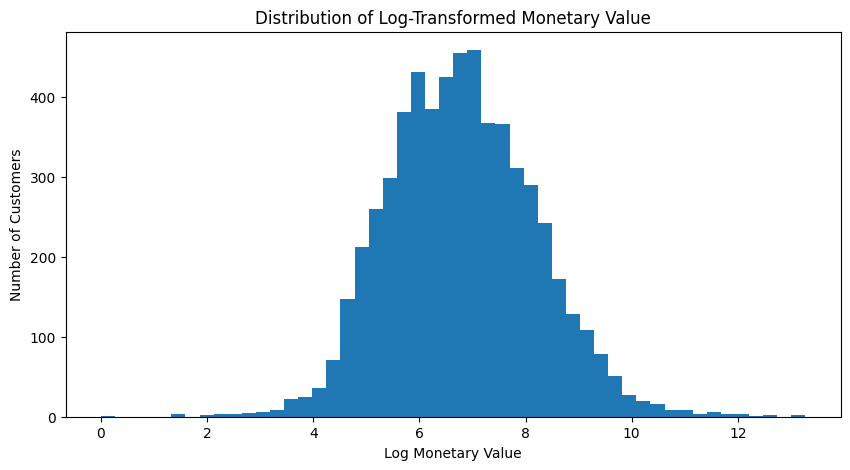

In [67]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_customers["Log_Monetary"],
    bins=50
)

plt.xlabel("Log Monetary Value")
plt.ylabel("Number of Customers")
plt.title("Distribution of Log-Transformed Monetary Value")

plt.show()

**Examine Relationships Between Behaviour Variables**-Which customer behaviours move together?

In [73]:
important_vars = [
    "Frequency",
    "Monetary",
    "Recency",
    "AverageOrderValue",
    "ProductDiversity",
    "CustomerTenure"
]

descriptive_summary = pd.DataFrame({
    "Mean": df_customers[important_vars].mean(),
    "Median": df_customers[important_vars].median(),
    "Q1": df_customers[important_vars].quantile(0.25),
    "Q3": df_customers[important_vars].quantile(0.75),
    "Std": df_customers[important_vars].std(),
    "Skewness": df_customers[important_vars].skew()
})

descriptive_summary.round(2)

,Mean,Median,Q1,Q3,Std,Skewness
Frequency,6.25,3.00,1.00,7.00,12.79,12.14
Monetary,2914.17,854.99,338.56,2236.94,14327.73,25.31
Recency,200.96,96.00,26.00,379.00,209.22,0.89
AverageOrderValue,382.77,277.52,175.75,410.52,1233.91,55.16
ProductDiversity,82.05,45.00,19.00,103.00,116.46,6.23
CustomerTenure,273.11,221.00,0.00,511.00,258.52,0.39


In [71]:
behaviour_vars = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "AverageBasketQuantity",
    "ProductDiversity",
    "CustomerTenure",
    "ReturnTransactions",
    "ReturnRate",
    "ActivePurchaseDays"
]

In [72]:
#Spearman correlation:Why Spearman instead of Pearson right now?

# Many of your variables are extremely skewed.

# Spearman correlation uses the rank/order of values rather than assuming a linear relationship between raw values, so it is more suitable for this first exploratory analysis.

spearman_corr = (
    df_customers[behaviour_vars]
    .corr(method="spearman")
)

spearman_corr.round(2)

,Recency,Frequency,Monetary,AverageOrderValue,AverageBasketQuantity,ProductDiversity,CustomerTenure,ReturnTransactions,ReturnRate,ActivePurchaseDays
Recency,1.00,-0.56,-0.51,-0.17,-0.20,-0.47,-0.57,-0.31,-0.20,-0.57
Frequency,-0.56,1.00,0.86,0.21,0.18,0.72,0.88,0.58,0.43,0.99
Monetary,-0.51,0.86,1.00,0.65,0.54,0.77,0.77,0.58,0.43,0.86
AverageOrderValue,-0.17,0.21,0.65,1.00,0.82,0.43,0.21,0.28,0.20,0.21
AverageBasketQuantity,-0.20,0.18,0.54,0.82,1.00,0.41,0.18,0.22,0.15,0.18
ProductDiversity,-0.47,0.72,0.77,0.43,0.41,1.00,0.66,0.45,0.31,0.71
CustomerTenure,-0.57,0.88,0.77,0.21,0.18,0.66,1.00,0.50,0.37,0.89
ReturnTransactions,-0.31,0.58,0.58,0.28,0.22,0.45,0.50,1.00,0.93,0.58
ReturnRate,-0.20,0.43,0.43,0.20,0.15,0.31,0.37,0.93,1.00,0.43
ActivePurchaseDays,-0.57,0.99,0.86,0.21,0.18,0.71,0.89,0.58,0.43,1.00


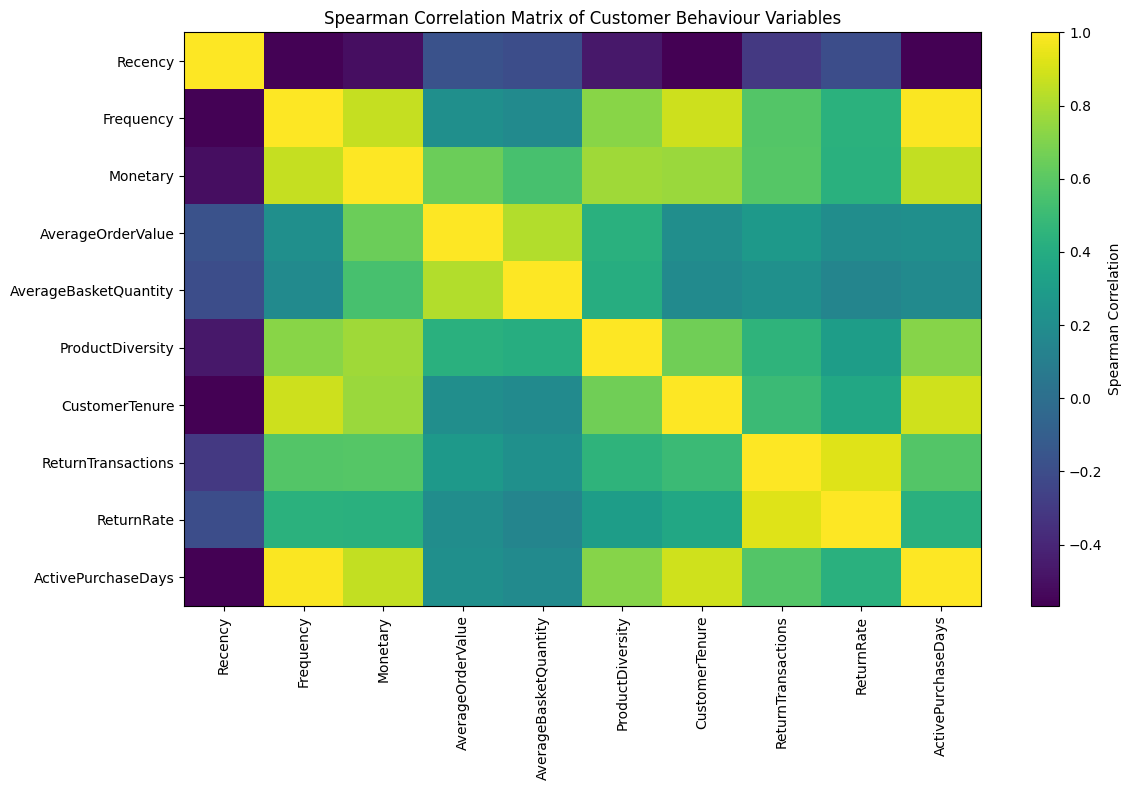

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.imshow(
    spearman_corr,
    aspect="auto"
)

plt.colorbar(label="Spearman Correlation")

plt.xticks(
    range(len(behaviour_vars)),
    behaviour_vars,
    rotation=90
)

plt.yticks(
    range(len(behaviour_vars)),
    behaviour_vars
)

plt.title(
    "Spearman Correlation Matrix of Customer Behaviour Variables"
)

plt.tight_layout()
plt.show()

**Descriptive Comparison: One-Time vs Repeat Customers**

This is useful because our main business problem is customer retention and repeat purchasing.

In [75]:
df_customers["CustomerGroup"] = np.where(
    df_customers["Frequency"] == 1,
    "One-time",
    "Repeat"
)

In [76]:
df_customers["CustomerGroup"].value_counts()

,count
CustomerGroup,
Repeat,4236
One-time,1627


In [77]:
group_summary = (
    df_customers
    .groupby("CustomerGroup")
    .agg(
        Customers=("CustomerID", "count"),
        MedianMonetary=("Monetary", "median"),
        MeanMonetary=("Monetary", "mean"),
        MedianRecency=("Recency", "median"),
        MedianProductDiversity=("ProductDiversity", "median"),
        MedianAverageOrderValue=("AverageOrderValue", "median"),
        MedianCustomerTenure=("CustomerTenure", "median"),
        MedianReturnRate=("ReturnRate", "median")
    )
)

group_summary.round(2)

#why use median -So the mean can be heavily affected by a few huge customers.

#The median gives us a better description of the typical customer in each group.

,Customers,MedianMonetary,MeanMonetary,MedianRecency,MedianProductDiversity,MedianAverageOrderValue,MedianCustomerTenure,MedianReturnRate
CustomerGroup,,,,,,,,
One-time,1627,227.10,342.27,387.0,16.0,227.10,0.0,0.0
Repeat,4236,1363.86,3902.01,59.0,66.0,291.29,382.0,0.0


In [ ]:
one_time_aov = df_customers.loc[
    df_customers["CustomerGroup"] == "One-time",
    "AverageOrderValue"
]

repeat_aov = df_customers.loc[
    df_customers["CustomerGroup"] == "Repeat",
    "AverageOrderValue"
]

In [ ]:
print("One-time customers:")
print(one_time_aov.describe())

print("\nRepeat customers:")
print(repeat_aov.describe())

One-time customers:
count     1627.000000
mean       342.270695
std        587.306581
min          0.000000
25%        135.975000
50%        227.100000
75%        368.800000
max      11880.840000
Name: AverageOrderValue, dtype: float64

Repeat customers:
count     4236.000000
mean       398.324145
std       1405.042344
min          3.725000
25%        192.866731
50%        291.286875
75%        424.252667
max      84236.250000
Name: AverageOrderValue, dtype: float64


In [ ]:
print(
    "One-time AOV skewness:",
    one_time_aov.skew()
)

print(
    "Repeat AOV skewness:",
    repeat_aov.skew()
)

One-time AOV skewness: 11.895742556878828
Repeat AOV skewness: 51.35652711274118
